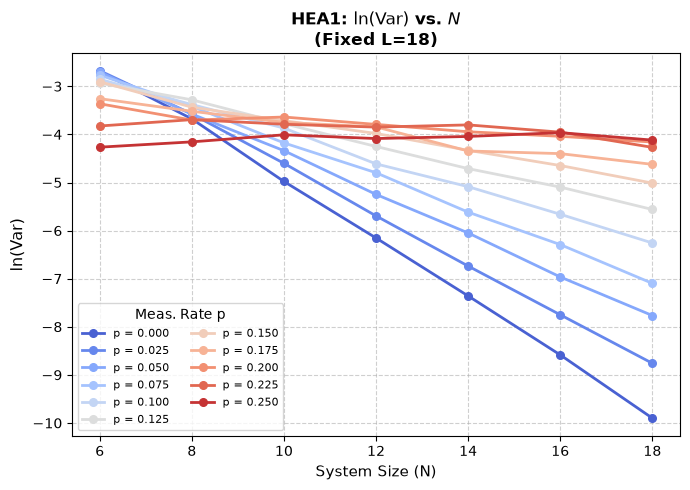

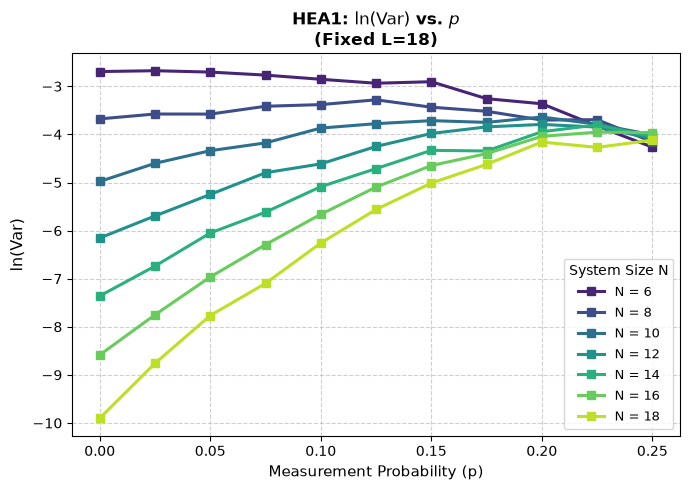

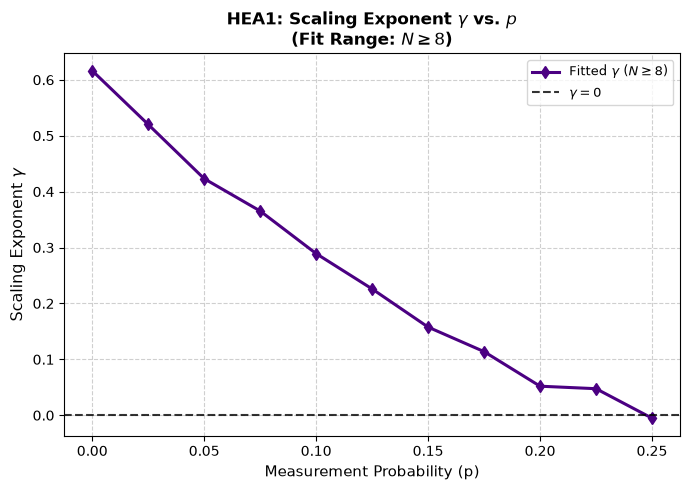

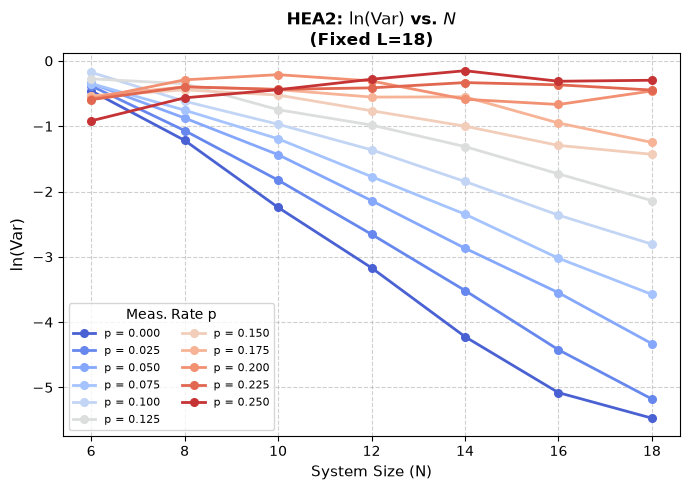

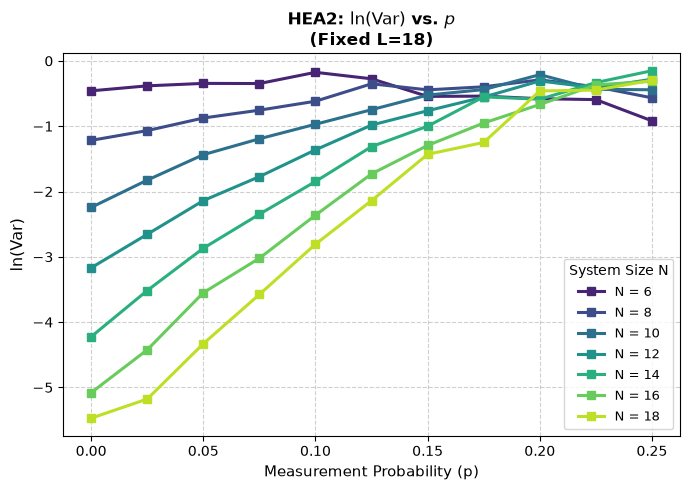

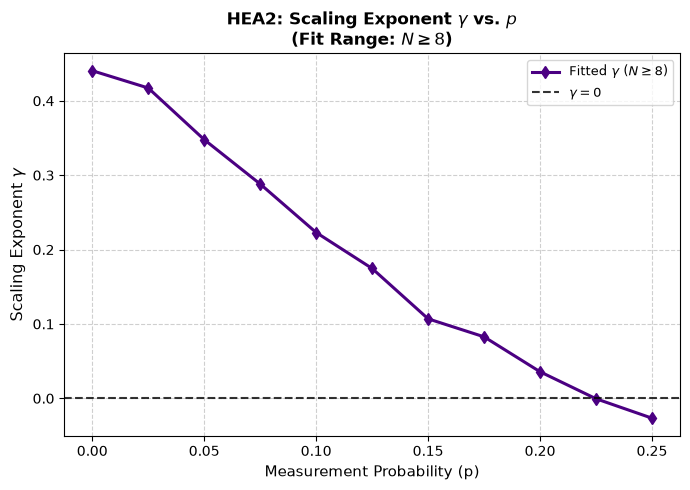

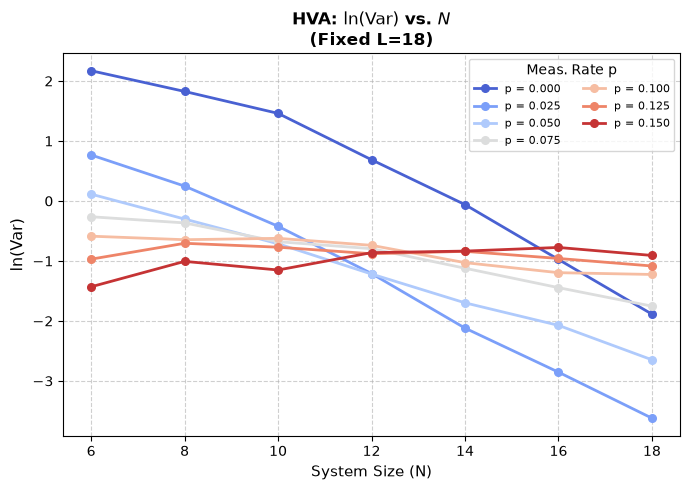

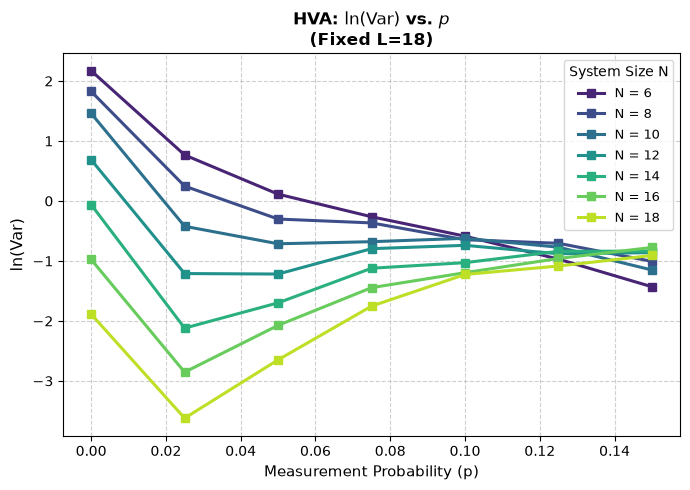

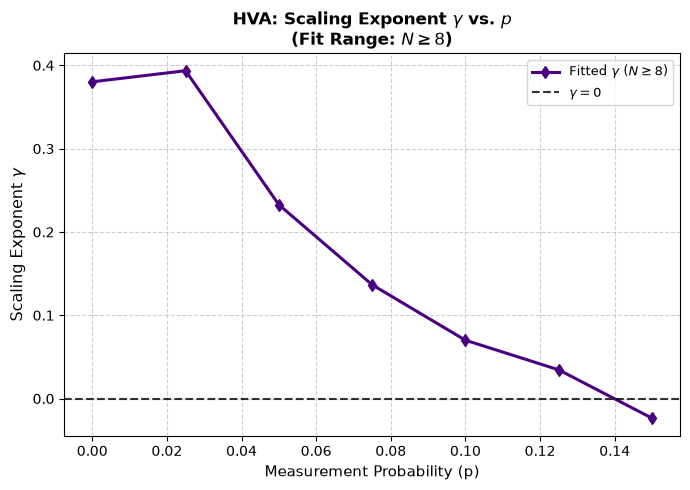

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

def plot_milt_custom_p(
    pkl_path="method1_weak_xxz_results.pkl",
    p_filter_by_ansatz=None,
    N_filter=None,
    plot_min_N=0,    # New parameter to control minimum N displayed in plots
    fit_min_N=6,     # Parameter to control minimum N used for calculating gamma
    tol=1e-4
):
    """
    Plots for a single measurement strength:
      1) ln(Var) vs N for selected p values (Individual plot per ansatz)
      2) ln(Var) vs p for selected N values (Individual plot per ansatz)
      3) Scaling exponent gamma vs p (Individual plot per ansatz)
    """
    with open(pkl_path, "rb") as f:
        data = pickle.load(f)

    ansatz_list = data["ansatz_list"]
    depth_desc = data.get("depth_desc", "Fixed L=18")

    # Handle both nested (variances[s][ansatz][p][N]) and flat (variances[ansatz][p][N]) structures gracefully
    raw_vars = data["variances"]
    if all(isinstance(k, (int, float)) for k in raw_vars.keys()):
        # If the outer keys are still 's' values, automatically extract the first/only one
        s_key = list(raw_vars.keys())[0]
        variances = raw_vars[s_key]
    else:
        variances = raw_vars

    def get_valid_ps_and_Ns(ansatz):
        if ansatz not in variances:
            return np.array([]), np.array([])
            
        avail_ps = sorted([
            float(p) for p, n_dict in variances[ansatz].items()
            if len(n_dict) > 0
        ])
        
        if p_filter_by_ansatz and ansatz in p_filter_by_ansatz and p_filter_by_ansatz[ansatz] is not None:
            filt = p_filter_by_ansatz[ansatz]
            if isinstance(filt, tuple) and len(filt) == 2:
                p_min, p_max = filt
                sel_ps = [p for p in avail_ps if (p_min - tol) <= p <= (p_max + tol)]
            else:
                sel_ps = [
                    p for p in avail_ps
                    if any(abs(p - target_p) <= tol for target_p in filt)
                ]
        else:
            sel_ps = avail_ps

        if not sel_ps:
            return np.array([]), np.array([])
            
        common_Ns = sorted(list(set.intersection(*[
            set(int(n) for n in variances[ansatz][p].keys()) for p in sel_ps
        ])))
        
        if N_filter is not None:
            common_Ns = [n for n in common_Ns if n in N_filter]
            
        return np.asarray(sel_ps, dtype=np.float64), np.asarray(common_Ns, dtype=np.int32)

    for ansatz in ansatz_list:
        p_sub, N_sub = get_valid_ps_and_Ns(ansatz)
        if len(p_sub) == 0 or len(N_sub) == 0:
            print(f"Skipping {ansatz}, no valid data.")
            continue
            
        # Apply the visual filter for minimum N
        N_sub_plot = N_sub[N_sub >= plot_min_N]
        if len(N_sub_plot) == 0:
            print(f"Skipping {ansatz} visualizations, no N >= {plot_min_N}.")
            continue

        # =========================================================================
        # 1. PLOT ln(Var) vs N FOR DIFFERENT p (Individual Figure)
        # =========================================================================
        plt.figure(figsize=(7, 5))
        cmap_p = plt.cm.coolwarm(np.linspace(0.05, 0.95, max(len(p_sub), 1)))

        for p_idx, p_val in enumerate(p_sub):
            var_vs_N = np.asarray([variances[ansatz][float(p_val)][int(N)] for N in N_sub_plot], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_N, 1e-30))
            plt.plot(N_sub_plot, ln_var, "o-", color=cmap_p[p_idx], lw=2.0, markersize=5.5, label=f"p = {p_val:.3f}")

        plt.title(f"{ansatz}: $\\ln(\\mathrm{{Var}})$ vs. $N$\n({depth_desc})", fontsize=12, fontweight="bold")
        plt.xlabel("System Size (N)", fontsize=11)
        plt.ylabel("$\\ln(\\mathrm{Var})$", fontsize=11.5)
        plt.xticks(N_sub_plot)
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.legend(loc="best", title="Meas. Rate p", fontsize=8, ncol=2)
        plt.tight_layout()
        plt.show()

        # =========================================================================
        # 2. PLOT ln(Var) vs p FOR DIFFERENT N (Individual Figure)
        # =========================================================================
        plt.figure(figsize=(7, 5))
        cmap_N = plt.cm.viridis(np.linspace(0.1, 0.9, max(len(N_sub_plot), 1)))

        for n_idx, N in enumerate(N_sub_plot):
            var_vs_p = np.asarray([variances[ansatz][float(p_val)][int(N)] for p_val in p_sub], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_p, 1e-30))
            plt.plot(p_sub, ln_var, "s-", color=cmap_N[n_idx], lw=2.2, markersize=5.5, label=f"N = {N}")

        plt.title(f"{ansatz}: $\\ln(\\mathrm{{Var}})$ vs. $p$\n({depth_desc})", fontsize=12, fontweight="bold")
        plt.xlabel("Measurement Probability (p)", fontsize=11)
        plt.ylabel("$\\ln(\\mathrm{Var})$", fontsize=11.5)
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.legend(loc="best", title="System Size N", fontsize=9.5)
        plt.tight_layout()
        plt.show()

        # =========================================================================
        # 3. PLOT gamma vs p (Individual Figure, Fit over N >= fit_min_N)
        # =========================================================================
        N_fit = N_sub[N_sub >= fit_min_N]
        if len(N_fit) < 2:
            print(f"Skipping {ansatz} gamma plot, insufficient N data for fitting (N >= {fit_min_N}).")
            continue

        plt.figure(figsize=(7, 5))
        gamma_list = []
        for p_val in p_sub:
            var_vs_N = np.asarray([variances[ansatz][float(p_val)][int(N)] for N in N_fit], dtype=np.float64)
            ln_var = np.log(np.maximum(var_vs_N, 1e-30))
            fit_params = np.polyfit(N_fit, ln_var, 1)
            gamma = -fit_params[0]
            gamma_list.append(gamma)

        plt.plot(p_sub, gamma_list, "d-", color="indigo", lw=2.2, markersize=6.5,
                 label=f"Fitted $\\gamma$ ($N \\geq {fit_min_N}$)")
        plt.axhline(y=0, color="black", linestyle="--", lw=1.5, alpha=0.8, label="$\\gamma = 0$")

        plt.title(f"{ansatz}: Scaling Exponent $\\gamma$ vs. $p$\n(Fit Range: $N \\geq {fit_min_N}$)", fontsize=12, fontweight="bold")
        plt.xlabel("Measurement Probability (p)", fontsize=11)
        plt.ylabel("Scaling Exponent $\\gamma$", fontsize=11.5)
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.legend(loc="best", fontsize=9.5)
        plt.tight_layout()
        plt.show()

# =============================================================================
# EXAMPLE USAGE
# =============================================================================

custom_p_bounds = {
    "HEA1": (0.00, 0.30),
    "HEA2": (0.00, 0.30),
    "HVA":  (0.00, 0.20),
}

plot_milt_custom_p(
    pkl_path="method1_weak_s_xxz_results_i.pkl",
    p_filter_by_ansatz=custom_p_bounds,
    plot_min_N=6,  # Filters visual plots to N >= 4
    fit_min_N=8    # Filters the scaling exponent fits to N >= 8
)